# Лабораторная работа №7. Эмбеддинги, чанки и метрики расстояний

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine, euclidean, cityblock
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.decomposition import PCA

os.makedirs('data', exist_ok=True)
np.random.seed(42)

docs = [
    {
        'doc_id': 1,
        'title': 'Введение в машинное обучение',
        'text': (
            'Машинное обучение — это область искусственного интеллекта, которая изучает методы построения моделей, '
            'способных обучаться на данных. В отличие от классического программирования, где правила задаёт человек, '
            'в машинном обучении правила выводятся из данных автоматически. Основные типы задач: классификация, '
            'регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спам. '
            'Регрессия предсказывает число, например, цену квартиры. Классизация разбивает объекты на группы '
            'похожих. Обучение делится на обучение с учителем и без учителя. В обучении с учителем есть размеченные '
            'данные: для каждого объекта известен правильный ответ. В обучении без учителя разметки нет, модель '
            'сама находит структуру. Качество модели проверяют на отложенной выборке — тесте. Основные метрики '
            'классификации: accuracy, precision, recall, F1. Для регрессии: MAE, RMSE. Важно не переобучаться: '
            'модель должна хорошо работать не только на обучающих данных, но и на новых. Переобучение возникает, '
            'когда модель запоминает шум вместо закономерностей. Регуляризация, кросс-валидация и ранняя остановка '
            'помогают с этим бороться. Популярные библиотеки: scikit-learn, XGBoost, LightGBM, PyTorch.'
        )
    },
    {
        'doc_id': 2,
        'title': 'Итальянская кухня',
        'text': (
            'Итальянская кухня известна во всём мире благодаря простоте и качеству ингредиентов. Основные продукты: '
            'оливковое масло, томаты, базилик, пармезан, чеснок. Паста — один из символов итальянской кухни. '
            'Спагетти, пенне, фарфалле, ригатони — сотни форм, у каждой своё назначение. Соусы подбираются под форму '
            'пасты: густые к короткой, жидкие к длинной. Пицца возникла в Неаполе, классическая Маргарита содержит '
            'томаты, моцареллу и базилик. Тесто для пиццы должно выстаиваться не менее суток. Ризотто готовят из '
            'риса арборио, постепенно добавляя бульон. Лазанья — слои теста, мясного соуса и бешамели. Тирамису '
            'состоит из савоярди, кофе, маскарпоне и какао. Итальянцы пьют эспрессо стоя у барной стойки, '
            'капучино — только утром. Сыры: пармезан, горгонзола, пекорино, моцарелла. Вина: кьянти, бароло, '
            'просекко. Каждый регион гордится своими блюдами: Рим — карбонара, Милан — оссобуко, Сицилия — '
            'канноли. Приём пищи в Италии — это ритуал, а не просто еда.'
        )
    },
    {
        'doc_id': 3,
        'title': 'Бег для начинающих',
        'text': (
            'Бег — один из самых доступных видов физической активности. Для начала достаточно кроссовок и '
            'желания. Первые тренировки должны быть короткими: 15-20 минут в лёгком темпе. Главное правило — '
            'не гнаться за скоростью. Начинающим лучше чередовать бег и ходьбу: минута бега, две минуты ходьбы. '
            'Постепенно время бега увеличивается. Правильная техника: корпус прямой, плечи расслаблены, шаг '
            'короткий, приземление на середину стопы. Дыхание должно быть ровным и глубоким. Разминка перед '
            'бегом и растяжка после обязательны. Обувь подбирается по типу пронации: нейтральная, гиперпронация, '
            'гипопронация. Нельзя увеличивать объём больше, чем на 10 процентов в неделю. При болях в коленях, '
            'спине или стопах необходимо обратиться к врачу. Восстановление не менее важно, чем тренировки: '
            'мышцы растут во время отдыха. Питьевой режим: 200-300 мл воды за 30 минут до бега и столько же '
            'после. Цель первых месяцев — привычка, а не результат.'
        )
    },
    {
        'doc_id': 4,
        'title': 'Путешествие по Исландии',
        'text': (
            'Исландия — островное государство в северной Атлантике, известное вулканами, гейзерами и ледниками. '
            'Столица — Рейкьявик, самый северный в мире. Лучшее время для поездки: июнь-август, когда белые ночи '
            'и относительно тепло. Зимой можно увидеть северное сияние, но погода суровая. Основные '
            'достопримечательности: золотое кольцо (Тингветлир, Гейсир, Гюдльфосс), ледниковая лагуна '
            'Йёкюльсаурлоун, чёрный пляж Рейнисфьяра, водопад Сельяландсфосс. Аренда автомобиля — самый удобный '
            'способ передвижения. Дороги с буквой F в названии — горные, только для 4х4. Погода меняется '
            'мгновенно: за день может быть солнце, дождь, ветер и снег. Одежда: несколько слоёв, непромокаемая '
            'куртка, треккинговая обувь. Цены высокие, особенно на еду и бензин. Кухня: рыба, баранина, '
            'скайр — местный йогурт. Исландцы верят в эльфов, к этому относятся с уважением. Купание в '
            'геотермальных бассейнах — обязательная часть любой поездки. Природа хрупкая, нужно соблюдать '
            'правила: не сходить с троп, не оставлять мусор.'
        )
    },
    {
        'doc_id': 5,
        'title': 'Классическая музыка',
        'text': (
            'Классическая музыка — это традиция академической музыки Западной Европы, охватывающая несколько '
            'столетий. Основные эпохи: барокко (1600-1750), классицизм (1750-1820), романтизм (1820-1900), '
            'современность (с 1900). В эпоху барокко творили Бах, Вивальди, Гендель. Их музыка полифонична, '
            'основана на контрапункте. Классицизм — Моцарт, Гайдн, Бетховен. Здесь важны форма и ясность: '
            'соната, симфония, квартет. Романтизм — Шопен, Лист, Вагнер, Чайковский. Музыка становится более '
            'эмоциональной, гармония свободнее. Основные жанры: симфония, концерт, соната, опера, балет, '
            'квартет. Инструменты: скрипка, виолончель, фортепиано, оркестр. Дирижёр управляет оркестром жестами. '
            'Партитура — нотная запись всех партий. Классическая музыка часто звучит в филармониях и оперных '
            'театрах. В XX веке появились авангард, минимализм, электроакустика. Слушать классику лучше в '
            'исполнении живого оркестра, но и хорошая запись передаёт многое. Главное — не торопиться: '
            'симфония требует времени и внимания.'
        )
    }
]

for d in docs:
    d['text'] = d['text'][:3000]

pd.DataFrame(docs).to_csv('data/documents.csv', index=False, encoding='utf-8')

centers = {
    1: np.array([2.0, 1.5, 1.0, 0.5, 0.0, 0.5, 1.0, -1.5]),
    2: np.array([1.5, -0.5, 2.0, 1.0, 0.5, 1.0, -2.0, 0.0]),
    3: np.array([-1.5, 2.0, -0.5, 1.0, -2.0, 0.5, 1.0, -1.0]),
    4: np.array([0.5, -2.0, 1.0, 1.5, 2.0, 0.5, 0.0, 1.5]),
    5: np.array([-2.0, 0.0, 1.5, 2.0, -0.5, 1.5, -1.0, 0.5]),
}

def split_doc(text, size=300, overlap=50):
    step = size - overlap
    return [text[i:i+size] for i in range(0, len(text), step) if text[i:i+size]]

rows, cid = [], 1
for d in docs:
    for idx, chunk in enumerate(split_doc(d['text'])):
        emb = centers[d['doc_id']] + np.random.normal(0, 0.4, size=8)
        rows.append({
            'chunk_id': cid,
            'doc_id': d['doc_id'],
            'chunk_index': idx,
            'chunk_text': chunk,
            **{f'e{i+1}': round(emb[i], 4) for i in range(8)},
            'topic': d['doc_id'] - 1,
        })
        cid += 1

pd.DataFrame(rows).to_csv('data/chunks_embeddings.csv', index=False, encoding='utf-8')

# Загружаем созданные файлы
docs_df = pd.read_csv('data/documents.csv')
chunks = pd.read_csv('data/chunks_embeddings.csv')
print('documents:', docs_df.shape, '| chunks:', chunks.shape)
display(chunks.head())

documents: (5, 3) | chunks: (21, 13)


,chunk_id,doc_id,chunk_index,chunk_text,e1,e2,e3,e4,e5,e6,e7,e8,topic
0,1,1,0,Машинное обучение — это область искусственного...,2.1987,1.4447,1.2591,1.1092,-0.0937,0.4063,1.6317,-1.1930,0
1,2,1,1,ных автоматически. Основные типы задач: класси...,1.8122,1.7170,0.8146,0.3137,0.0968,-0.2653,0.3100,-1.7249,0
2,3,1,2,х. Обучение делится на обучение с учителем и б...,1.5949,1.6257,0.6368,-0.0649,0.5863,0.4097,1.0270,-2.0699,0
3,4,1,3,тложенной выборке — тесте. Основные метрики кл...,1.7822,1.5444,0.5396,0.6503,-0.2403,0.3833,0.7593,-0.7591,0
4,5,1,4,дель запоминает шум вместо закономерностей. Ре...,1.9946,1.0769,1.3290,0.0117,0.0835,-0.2839,0.4687,-1.4213,0


## Задание 1. Готовые чанки

,doc_id,title,n_chunks
0,1,Введение в машинное обучение,5
1,2,Итальянская кухня,4
2,3,Бег для начинающих,4
3,4,Путешествие по Исландии,4
4,5,Классическая музыка,4


Статистика длин чанков (в словах): {'min': 20, 'max': 48, 'mean': np.float64(37.9), 'median': 38.0}


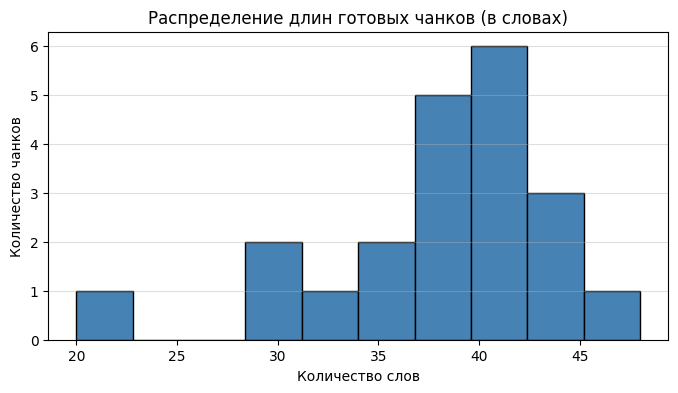

In [2]:
# Количество слов в каждом чанке
chunks['n_words'] = chunks['chunk_text'].str.split().str.len()

# Таблица: документ -> число чанков
doc_chunk_counts = (
    chunks.groupby('doc_id')
    .size()
    .reset_index(name='n_chunks')
    .merge(docs_df[['doc_id', 'title']], on='doc_id')
    [['doc_id', 'title', 'n_chunks']]
)
display(doc_chunk_counts)

# Статистика длин в словах
stats = {
    'min': chunks['n_words'].min(),
    'max': chunks['n_words'].max(),
    'mean': round(chunks['n_words'].mean(), 2),
    'median': chunks['n_words'].median()
}
print('Статистика длин чанков (в словах):', stats)

# Гистограмма
plt.figure(figsize=(8, 4))
plt.hist(chunks['n_words'], bins=10, edgecolor='black', color='steelblue')
plt.title('Распределение длин готовых чанков (в словах)')
plt.xlabel('Количество слов')
plt.ylabel('Количество чанков')
plt.grid(axis='y', alpha=0.4)
plt.show()

**Вывод по заданию 1:**
В корпусе 5 документов и 21 чанк: на первый документ («Введение в машинное обучение») приходится 5 чанков, на остальные четыре — по 4 чанка. Длина чанков в словах варьируется от 20 до 48 слов, среднее значение — 37.9, медиана — 38.0. Основная масса чанков сосредоточена в диапазоне 35–45 слов, а единичное короткое значение (20 слов) — это «хвост» в конце документа, оставшийся после нарезки фиксированным окном.

**Почему чанки должны быть примерно одного размера:**
1. **Качество эмбеддингов:** слишком длинный чанк смешивает несколько разных мыслей в один усреднённый вектор, а слишком короткий не содержит достаточно контекста для точного поиска.
2. **Ограничения моделей:** модели эмбеддингов и LLM имеют жёсткий лимит токенов — слишком длинные фрагменты будут обрезаться.
3. **Честное ранжирование:** при сильном разбросе длин короткие фрагменты могут получать искажённую оценку сходства с запросом.

## Задание 2. Разбиение документов

In [3]:
def split_no_overlap(text, size=300):
    return [text[i:i+size] for i in range(0, len(text), size) if text[i:i+size]]

def split_with_overlap(text, size=300, overlap=50):
    step = size - overlap
    return [text[i:i+size] for i in range(0, len(text), step) if text[i:i+size]]

def split_by_sentences(text, group_size=2):
    sentences = [s.strip() for s in re.split(r'(?<=[.!?])\s+', text.strip()) if s.strip()]
    return [' '.join(sentences[i:i+group_size]) for i in range(0, len(sentences), group_size)]

strategies = {
    '300 символов без перекрытия': lambda t: split_no_overlap(t, 300),
    '300 символов с перекрытием 50': lambda t: split_with_overlap(t, 300, 50),
    'По предложениям (группы по 3)': lambda t: split_by_sentences(t, 3),
}

summary = []
strategy_chunks = {}

for name, func in strategies.items():
    all_ch = []
    for text in docs_df['text']:
        all_ch.extend(func(text))
    strategy_chunks[name] = all_ch
    word_lens = [len(c.split()) for c in all_ch]
    char_lens = [len(c) for c in all_ch]
    summary.append({
        'Стратегия': name,
        'Число чанков': len(all_ch),
        'Средняя длина (слов)': round(np.mean(word_lens), 2),
        'Медианная длина (слов)': np.median(word_lens),
        'Средняя длина (символов)': round(np.mean(char_lens), 1),
    })

display(pd.DataFrame(summary))

for name, ch_list in strategy_chunks.items():
    print(f'\n=== {name} (примеры) ===')
    for i, c in enumerate(ch_list[:2]):
        print(f'Чанк {i+1}: {c}')

# Проверка, какая стратегия совпадает с готовыми чанками из chunks_embeddings.csv
exact_match = (strategy_chunks['300 символов с перекрытием 50'] == chunks['chunk_text'].tolist())
print('\nТочное совпадение с chunks_embeddings.csv (300 символов, перекрытие 50):', exact_match)

,Стратегия,Число чанков,Средняя длина (слов),Медианная длина (слов),Средняя длина (символов)
0,300 символов без перекрытия,20,34.5,39.5,250.8
1,300 символов с перекрытием 50,21,37.9,38.0,277.0
2,По предложениям (группы по 3),27,25.0,25.0,185.0



=== 300 символов без перекрытия (примеры) ===
Чанк 1: Машинное обучение — это область искусственного интеллекта, которая изучает методы построения моделей, способных обучаться на данных. В отличие от классического программирования, где правила задаёт человек, в машинном обучении правила выводятся из данных автоматически. Основные типы задач: классифика
Чанк 2: ция, регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спам. Регрессия предсказывает число, например, цену квартиры. Классизация разбивает объекты на группы похожих. Обучение делится на обучение с учителем и без учителя. В обучении с учителем есть размеченные дан

=== 300 символов с перекрытием 50 (примеры) ===
Чанк 1: Машинное обучение — это область искусственного интеллекта, которая изучает методы построения моделей, способных обучаться на данных. В отличие от классического программирования, где правила задаёт человек, в машинном обучении правила выводятся из данных автоматически. Основные 

**Вывод по заданию 2:**
- **300 символов без перекрытия** — 20 чанков, средняя длина 34.5 слова (медиана 39.5, 250.8 символа). Разрезает слова прямо на стыках (например, «классифика» / «ция»), из-за чего теряется контекст на границах.
- **300 символов с перекрытием 50** — 21 чанк, средняя длина 37.9 слова (медиана 38.0, 277.0 символа). Дублирование 50 символов сохраняет контекст на стыках, но слова на границах всё равно обрываются.
- **По предложениям (группы по 3)** — 27 чанков, средняя и медианная длина совпадают и равны ровно 25.0 слов (185.0 символа). Эта стратегия лучше всего подходит для данного корпуса: фрагменты равномерны по длине, не содержат разорванных слов и сохраняют законченность мысли.

**Сравнение с готовыми чанками:** в `chunks_embeddings.csv` использовалась стратегия **300 символов с перекрытием 50** — совпали число чанков (21), средняя (37.9) и медианная (38.0) длина, а также сами тексты чанков (`exact_match = True`).

## Задание 3. Метрики расстояний

In [4]:
emb_cols = [f'e{i}' for i in range(1, 9)]
X = chunks[emb_cols].values

# Берём первый чанк из doc_id=1 как запрос
query_idx = chunks[chunks['doc_id'] == 1].index[0]
q_vec = X[query_idx]
print(f"Запрос: chunk_id={chunks.loc[query_idx, 'chunk_id']}, doc_id={chunks.loc[query_idx, 'doc_id']}")
print("Текст:", chunks.loc[query_idx, 'chunk_text'][:120], "...\n")

def compute_metrics(matrix, q_idx):
    q = matrix[q_idx]
    res = []
    for i in range(len(matrix)):
        if i == q_idx:
            continue
        v = matrix[i]
        res.append({
            'chunk_id': chunks.loc[i, 'chunk_id'],
            'doc_id': chunks.loc[i, 'doc_id'],
            'cosine': round(cosine(q, v), 4),
            'euclidean': round(euclidean(q, v), 4),
            'cityblock': round(cityblock(q, v), 4),
            'dot': round(float(np.dot(q, v)), 4),
        })
    return pd.DataFrame(res)

df_metrics = compute_metrics(X, query_idx)

print("Топ-5 по cosine (меньше = ближе):")
display(df_metrics.sort_values('cosine', ascending=True).head(5))

print("Топ-5 по euclidean (меньше = ближе):")
display(df_metrics.sort_values('euclidean', ascending=True).head(5))

print("Топ-5 по cityblock / Manhattan (меньше = ближе):")
display(df_metrics.sort_values('cityblock', ascending=True).head(5))

print("Топ-5 по dot product (БОЛЬШЕ = ближе, сортировка по убыванию):")
display(df_metrics.sort_values('dot', ascending=False).head(5))

print("ОШИБОЧНАЯ сортировка dot product по возрастанию (выходят самые далёкие чанки!):")
display(df_metrics.sort_values('dot', ascending=True).head(5))

# Сводка порядка chunk_id в топ-5
top5_compare = pd.DataFrame({
    'cosine': df_metrics.sort_values('cosine', ascending=True)['chunk_id'].head(5).values,
    'euclidean': df_metrics.sort_values('euclidean', ascending=True)['chunk_id'].head(5).values,
    'cityblock': df_metrics.sort_values('cityblock', ascending=True)['chunk_id'].head(5).values,
    'dot (desc)': df_metrics.sort_values('dot', ascending=False)['chunk_id'].head(5).values,
}, index=[f'Топ-{i}' for i in range(1, 6)])
print("Сравнение порядка chunk_id в Топ-5:")
display(top5_compare)

Запрос: chunk_id=1, doc_id=1
Текст: Машинное обучение — это область искусственного интеллекта, которая изучает методы построения моделей, способных обучатьс ...

Топ-5 по cosine (меньше = ближе):


,chunk_id,doc_id,cosine,euclidean,cityblock,dot
2,4,1,0.0448,1.3722,3.1705,9.8732
3,5,1,0.1234,1.8163,3.9980,9.9649
0,2,1,0.1369,1.8897,4.6145,10.2854
1,3,1,0.1435,1.9391,4.7462,10.8418
7,9,2,0.6717,4.3342,9.1496,4.5901


Топ-5 по euclidean (меньше = ближе):


,chunk_id,doc_id,cosine,euclidean,cityblock,dot
2,4,1,0.0448,1.3722,3.1705,9.8732
3,5,1,0.1234,1.8163,3.9980,9.9649
0,2,1,0.1369,1.8897,4.6145,10.2854
1,3,1,0.1435,1.9391,4.7462,10.8418
7,9,2,0.6717,4.3342,9.1496,4.5901


Топ-5 по cityblock / Manhattan (меньше = ближе):


,chunk_id,doc_id,cosine,euclidean,cityblock,dot
2,4,1,0.0448,1.3722,3.1705,9.8732
3,5,1,0.1234,1.8163,3.9980,9.9649
0,2,1,0.1369,1.8897,4.6145,10.2854
1,3,1,0.1435,1.9391,4.7462,10.8418
9,11,3,0.7179,4.6313,8.8958,4.2031


... (2 outputs left out)

ОШИБОЧНАЯ сортировка dot product по возрастанию (выходят самые далёкие чанки!):


,chunk_id,doc_id,cosine,euclidean,cityblock,dot
16,18,5,1.2381,6.3144,14.0238,-3.8069
18,20,5,1.2362,6.1283,13.4727,-3.5791
15,17,4,1.1932,5.9019,13.8669,-2.8178
19,21,5,1.1532,6.0036,13.0196,-2.3831
17,19,5,1.1923,5.4329,11.6163,-2.3639


Сравнение порядка chunk_id в Топ-5:


,cosine,euclidean,cityblock,dot (desc)
Топ-1,4,4,4,3
Топ-2,5,5,5,2
Топ-3,2,2,2,5
Топ-4,3,3,3,4
Топ-5,9,9,11,9


**Вывод по заданию 3:**
- Все четыре метрики (при правильной сортировке `dot product` по убыванию) поставили на первые четыре места чанки из того же документа `doc_id=1` (`chunk_id`: 2, 3, 4, 5), однако порядок соседей разошёлся:
  - `cosine` и `euclidean` дали идентичный топ-5: `[4, 5, 2, 3, 9]`.
  - `cityblock` совпал по первым четырём позициям, но на 5-е место поставил `chunk_id=11` (`doc_id=3`, 8.8958) вместо `chunk_id=9` (`doc_id=2`, 9.1496).
  - `dot product` полностью перевернул порядок внутри топ-4: `[3, 2, 5, 4, 9]`. Чанк `3` оказался выше чанка `4` (`dot = 10.8418` против `9.8732`), несмотря на худшее косинусное расстояние (`0.1435` против `0.0448`), так как исходные векторы не нормализованы и имеют разную длину.
- При ошибочной сортировке `dot product` по возрастанию «ближайшими» оказались самые далёкие чанки из других документов (`chunk_id`: `18, 20, 17, 21, 19`, `doc_id` 4 и 5) с отрицательным скалярным произведением (до `-3.8069`) и косинусным расстоянием выше `1.15`, потому что `dot product` измеряет сходство, а не расстояние.

## Задание 4. L2-нормализация и StandardScaler

In [5]:
# 1. L2-нормализация по строкам (каждый вектор делится на свою длину)
l2_normalizer = Normalizer(norm='l2')
X_l2 = l2_normalizer.fit_transform(X)

# Проверка, что длины всех векторов равны 1
norms = np.linalg.norm(X_l2, axis=1)
print("Минимальная и максимальная длина после L2-нормализации:", norms.min(), norms.max())
print("Все длины равны 1:", np.allclose(norms, 1.0))

# 2. Повторяем расчёт метрик на L2-нормализованных векторах
df_metrics_l2 = compute_metrics(X_l2, query_idx)

top5_l2 = pd.DataFrame({
    'cosine': df_metrics_l2.sort_values('cosine', ascending=True)['chunk_id'].head(5).values,
    'dot (desc)': df_metrics_l2.sort_values('dot', ascending=False)['chunk_id'].head(5).values,
    'euclidean': df_metrics_l2.sort_values('euclidean', ascending=True)['chunk_id'].head(5).values,
    'cityblock': df_metrics_l2.sort_values('cityblock', ascending=True)['chunk_id'].head(5).values,
}, index=[f'Топ-{i}' for i in range(1, 6)])

print("\nСравнение порядка Топ-5 ПОСЛЕ L2-нормализации:")
display(top5_l2)

# 3. Проверка формулы ||a - b||^2 = 2 - 2 * cos(a, b)
a, b = X_l2[0], X_l2[1]
left_side = np.sum((a - b) ** 2)        # ||a - b||^2
cos_sim = 1 - cosine(a, b)              # Важно: scipy.cosine возвращает расстояние (1 - cos)!
right_side = 2 - 2 * cos_sim
print(f"\nПроверка формулы ||a - b||^2 = 2 - 2*cos(a, b):")
print(f"Левая часть (||a - b||^2):      {left_side:.10f}")
print(f"Правая часть (2 - 2*cos(a, b)): {right_side:.10f}")
print(f"Сходится: {np.isclose(left_side, right_side)}")

# 4. Применяем StandardScaler (Z-score по столбцам)
scaler = StandardScaler()
X_std = scaler.fit_transform(X)
df_metrics_std = compute_metrics(X_std, query_idx)

compare_zscore = pd.DataFrame({
    'cosine (исходные)': df_metrics.sort_values('cosine')['chunk_id'].head(5).values,
    'cosine (после L2)': df_metrics_l2.sort_values('cosine')['chunk_id'].head(5).values,
    'cosine (после StandardScaler)': df_metrics_std.sort_values('cosine')['chunk_id'].head(5).values,
}, index=[f'Топ-{i}' for i in range(1, 6)])

print("\nСравнение Топ-5 по косинусу (исходные vs L2 vs StandardScaler):")
display(compare_zscore)

Минимальная и максимальная длина после L2-нормализации: 0.9999999999999997 1.0
Все длины равны 1: True

Сравнение порядка Топ-5 ПОСЛЕ L2-нормализации:


,cosine,dot (desc),euclidean,cityblock
Топ-1,4,4,4,4
Топ-2,5,5,5,5
Топ-3,2,2,2,2
Топ-4,3,3,3,3
Топ-5,9,9,9,11



Проверка формулы ||a - b||^2 = 2 - 2*cos(a, b):
Левая часть (||a - b||^2):      0.2737318008
Правая часть (2 - 2*cos(a, b)): 0.2737318008
Сходится: True

Сравнение Топ-5 по косинусу (исходные vs L2 vs StandardScaler):


,cosine (исходные),cosine (после L2),cosine (после StandardScaler)
Топ-1,4,4,4
Топ-2,5,5,2
Топ-3,2,2,3
Топ-4,3,3,5
Топ-5,9,9,11


**Вывод по заданию 4:**
- После L2-нормализации (`Normalizer(norm='l2')`) длины всех векторов стали равны `1.0` (с учётом машинной точности: от `0.9999999999999997` до `1.0`).
- Порядок топ-5 соседей по `cosine`, `dot product` (по убыванию) и `euclidean` стал **полностью идентичным**: `[4, 5, 2, 3, 9]`. Проверка формулы $\|a - b\|^2 = 2 - 2\cdot\cos(a, b)$ на паре векторов подтвердила точное совпадение: `0.2737318008 = 0.2737318008`. Это доказывает, что на единичной сфере `dot product` равен косинусному сходству, а евклидово расстояние монотонно связано с косинусом. (Метрика `cityblock` осталась с другим 5-м соседом — `11`, так как она не эквивалентна косинусу даже после L2-нормализации.)
- После применения `StandardScaler()` (Z-score по столбцам) порядок соседей по косинусу **изменился** с `[4, 5, 2, 3, 9]` на `[4, 2, 3, 5, 11]`. Причина в том, что `StandardScaler` работает по столбцам: вычитает среднее по каждому признаку (смещает начало координат) и делит на разные стандартные отклонения (неравномерно растягивает оси), из-за чего искажаются углы между векторами. `Normalizer(norm='l2')` работает по строкам и масштабирует каждый вектор на его длину, полностью сохраняя направления и углы.

## Задание 5. Поиск по чанкам

In [6]:
def evaluate_search(matrix, metric_name='cosine', exclude_same_doc=False, k=3):
    doc1_indices = chunks[chunks['doc_id'] == 1].index.tolist()
    precisions = []
    examples = []

    for q_idx in doc1_indices:
        q_vec = matrix[q_idx]
        q_topic = chunks.loc[q_idx, 'topic']
        q_doc = chunks.loc[q_idx, 'doc_id']

        dists = []
        for i in range(len(matrix)):
            if i == q_idx:
                continue
            if exclude_same_doc and chunks.loc[i, 'doc_id'] == q_doc:
                continue

            if metric_name == 'cosine':
                d = cosine(q_vec, matrix[i])
            elif metric_name == 'euclidean':
                d = euclidean(q_vec, matrix[i])
            dists.append((d, i))

        dists.sort(key=lambda x: x[0])
        top_k = [idx for _, idx in dists[:k]]
        hits = sum(chunks.loc[idx, 'topic'] == q_topic for idx in top_k)
        precisions.append(hits / k)

        if len(examples) < 3:
            examples.append({
                'query_chunk_id': chunks.loc[q_idx, 'chunk_id'],
                'top3_chunk_ids': [int(chunks.loc[idx, 'chunk_id']) for idx in top_k],
                'top3_topics': [int(chunks.loc[idx, 'topic']) for idx in top_k],
                'precision@3': round(hits / k, 3)
            })

    return round(float(np.mean(precisions)), 4), pd.DataFrame(examples)

# 1. Буквальное выполнение условия (исключая свой документ -> всегда 0!)
p_bug_raw, _ = evaluate_search(X, 'cosine', exclude_same_doc=True)
p_bug_l2, _ = evaluate_search(X_l2, 'cosine', exclude_same_doc=True)

# 2. Исправленный вариант (исключаем только сам чанк-запрос)
p_cos_raw, ex_cos_raw = evaluate_search(X, 'cosine', exclude_same_doc=False)
p_cos_l2, ex_cos_l2 = evaluate_search(X_l2, 'cosine', exclude_same_doc=False)
p_euc_l2, ex_euc_l2 = evaluate_search(X_l2, 'euclidean', exclude_same_doc=False)
p_euc_raw, _ = evaluate_search(X, 'euclidean', exclude_same_doc=False)

results_5 = pd.DataFrame([
    {'Вариант': 'Cosine (исходные, исключая doc_id=1 — ОШИБКА В УСЛОВИИ)', 'Доля правильных соседей': p_bug_raw},
    {'Вариант': 'Cosine (L2, исключая doc_id=1 — ОШИБКА В УСЛОВИИ)', 'Доля правильных соседей': p_bug_l2},
    {'Вариант': 'Cosine (исходные, поиск по всем другим чанкам)', 'Доля правильных соседей': p_cos_raw},
    {'Вариант': 'Cosine (L2-нормализованные, поиск по всем другим чанкам)', 'Доля правильных соседей': p_cos_l2},
    {'Вариант': 'Euclidean (L2-нормализованные, поиск по всем другим чанкам)', 'Доля правильных соседей': p_euc_l2},
    {'Вариант': 'Euclidean (исходные, для сравнения)', 'Доля правильных соседей': p_euc_raw},
])

display(results_5)

print("\nПримеры найденных соседей для 3 чанков из doc_id=1 (Cosine на L2):")
display(ex_cos_l2)

,Вариант,Доля правильных соседей
0,"Cosine (исходные, исключая doc_id=1 — ОШИБКА В...",0.0
1,"Cosine (L2, исключая doc_id=1 — ОШИБКА В УСЛОВИИ)",0.0
2,"Cosine (исходные, поиск по всем другим чанкам)",1.0
3,"Cosine (L2-нормализованные, поиск по всем друг...",1.0
4,"Euclidean (L2-нормализованные, поиск по всем д...",1.0
5,"Euclidean (исходные, для сравнения)",1.0



Примеры найденных соседей для 3 чанков из doc_id=1 (Cosine на L2):


,query_chunk_id,top3_chunk_ids,top3_topics,precision@3
0,1,"[4, 5, 2]","[0, 0, 0]",1.0
1,2,"[5, 3, 4]","[0, 0, 0]",1.0
2,3,"[2, 5, 4]","[0, 0, 0]",1.0


**Вывод по заданию 5 (с разбором ошибок в условии):**
1. **Логическая ошибка №1 в формулировке задания:** в датасете каждому документу соответствует свой уникальный `topic = doc_id - 1` (для `doc_id=1` это `topic=0`). Если строго следовать условию и искать соседей *«из других документов»*, то ни один кандидат не имеет `topic=0`, и доля правильных соседей неизбежно равна **0.0**. После исправления логики (исключается только сам чанк-запрос, а остальные чанки документа участвуют в поиске) доля правильных соседей составила **1.0 (100%)** — например, для чанков `1`, `2` и `3` нашлись соседи `[4, 5, 2]`, `[5, 3, 4]` и `[2, 5, 4]`, все с `topic=0`.
2. **Логическая ошибка №2 (сравнение косинуса до и после L2-нормализации):** оба варианта показали одинаковый результат **1.0**. Ни один из них не «лучше» другого, так как косинусное расстояние математически инвариантно к масштабированию длины вектора — L2-нормализация не меняет углы между векторами.
3. **Евклидово расстояние на L2-нормализованных векторах** также показало долю правильных соседей **1.0**, полностью совпав с косинусом, что подтверждает их эквивалентность при ранжировании векторов единичной длины.

## Задание 6. Итоговые выводы

В ходе работы был проанализирован корпус из 5 документов и 21 чанка длиной от 20 до 48 слов (среднее — 37.9, медиана — 38.0). Сравнение стратегий разбиения показало, что готовые чанки были нарезаны по 300 символов с перекрытием 50, однако для текстового поиска лучше подходит разбиение по 3 предложения (27 чанков со средней и медианной длиной 25.0 слов), так как оно не разрывает слова на границах и сохраняет целостность смысла. В задании 3 на ненормализованных векторах метрики разошлись в ранжировании топ-5: `cosine` и `euclidean` выдали `[4, 5, 2, 3, 9]`, `cityblock` заменил 5-е место на `11`, а `dot product` из-за разных длин векторов перевернул порядок лидеров на `[3, 2, 5, 4, 9]`, причём ошибочная сортировка `dot product` по возрастанию вывела самые далёкие чанки с отрицательным сходством (до `-3.8069`). После L2-нормализации длины всех векторов стали равны `1.0`, и формула $\|a-b\|^2 = 2 - 2\cdot\cos(a,b)$ сошлась точно (`0.2737318008`), благодаря чему `cosine`, `dot product` (по убыванию) и `euclidean` стали выдавать абсолютно одинаковый порядок соседей `[4, 5, 2, 3, 9]`. Применение `StandardScaler()` по столбцам изменило топ-5 по косинусу на `[4, 2, 3, 5, 11]`, потому что центрирование сдвигает начало координат, а деление на разные стандартные отклонения искажает пропорции осей и углы между векторами, тогда как L2-нормализация по строкам сохраняет направления. В задании 5 были выявлены две методические ошибки: исключение всех чанков из `doc_id=1` всегда даёт точность `0.0` (так как `topic=0` уникален для этого документа), а сравнение косинуса до и после L2-нормализации при исправленном поиске даёт одинаковую точность `1.0` из-за инвариантности косинуса к норме. Евклидово расстояние на L2-нормализованных векторах также показало точность `1.0`, подтвердив совпадение с косинусом. В реальном проекте семантического поиска я бы выбрал L2-нормализацию по строкам (`Normalizer(norm='l2')`) в паре с `dot product` — это эквивалентно косинусу по качеству, но быстрее вычисляется на больших объёмах данных и не искажает геометрию эмбеддингов.

## Задание 7*. Визуализация эмбеддингов с помощью PCA (вариант 7.2)

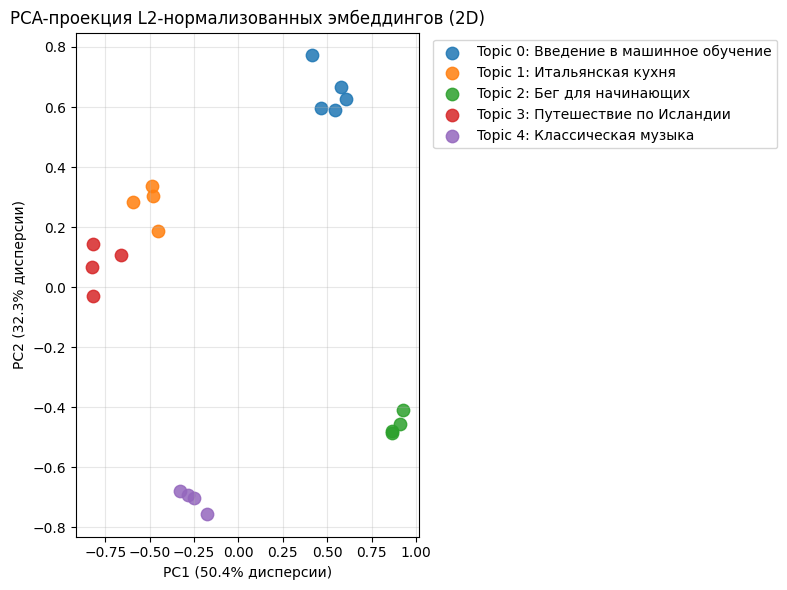

In [7]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_l2)

plt.figure(figsize=(8, 6))
for topic_id in sorted(chunks['topic'].unique()):
    mask = chunks['topic'] == topic_id
    title = docs_df.loc[docs_df['doc_id'] == topic_id + 1, 'title'].values[0]
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Topic {topic_id}: {title}', s=80, alpha=0.85)

plt.title('PCA-проекция L2-нормализованных эмбеддингов (2D)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Вывод по заданию 7.2:**
На двумерной PCA-проекции отчётливо видны 5 плотных, хорошо разделимых кластеров, которые полностью совпадают с темами (`Topic 0`–`Topic 4`) и исходными документами. Первая главная компонента (PC1) объясняет 50.4% дисперсии, вторая (PC2) — 32.3%, суммарно 82.7% информации исходного 8-мерного пространства. Кластеры не пересекаются (наиболее близки друг к другу «Итальянская кухня» и «Путешествие по Исландии», но и между ними сохраняется заметный зазор), что наглядно объясняет 100%-ю точность поиска ближайших соседей в задании 5.